In [1]:
from typing import List

import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl


In [87]:
class Module:
	def forward(self, x):
		raise NotImplementedError

	def backward(self, grad):
		raise NotImplementedError

	def adjust(self, eta):
		raise NotImplementedError


class LinearLayer(Module):
	def __init__(self, input_size: int, output_size: int, weights: None | np.ndarray = None,
	             biases: None | np.ndarray = None):
		if weights is not None:
			if weights.shape != (input_size, output_size):
				raise ValueError("niezgodne wymiary macierzy wag")
			self.W = np.copy(weights)
		else:
			self.W = np.random.randn(input_size, output_size) * 0.1
		if biases is not None:
			biases = np.atleast_2d(biases)  # Wymuszenie kształtu (1, output_size)
			if biases.shape != (1, output_size):
					raise ValueError("niezgodne wymiary macierzy biasow")
			self.b = np.copy(biases)
		else:
			self.b = np.zeros((1, output_size))

		self.b = None
		self.cache_X = None
		self.cache_grad = None

	def forward(self, x):
		self.cache_X = np.atleast_2d(x)
		if self.b is not None:
			return self.cache_X @ self.W + self.b
		return self.cache_X @ self.W
	def backward(self, grad):
		self.cache_grad = grad
		return grad @ self.W.T

	def adjust(self, eta):
		self.W -= eta * (self.cache_X.T @ self.cache_grad)
		if self.b is not None:
			self.b -= eta * np.sum(self.cache_grad, axis=0, keepdims=True)


class ActivationLayer(Module):

	@staticmethod
	def relu(x: np.ndarray) -> np.ndarray:
		return np.maximum(x, 0)

	@staticmethod
	def relu_derivative(x: np.ndarray) -> np.ndarray:
		return np.where(x > 0, 1.0, 0)

	ACTIVATION_FUNCTIONS = {
		'ReLU': (relu, relu_derivative)
	}

	def __init__(self, activation_function):
		self.activation_function = self.ACTIVATION_FUNCTIONS[activation_function][0]
		self.derivative_function = self.ACTIVATION_FUNCTIONS[activation_function][1]
		self.cache_S = None

	def forward(self, S):
		self.cache_S = S
		return self.activation_function(S)

	def backward(self, grad):
		return grad * self.derivative_function(self.cache_S)

	def adjust(self, eta):
		pass


class NeuralNetworkException(Exception):
	def __init__(self, msg):
		self.messege = msg

	def get_message(self):
		return self.messege


class NeuralNetwork:

	def __init__(self, initial_input_size):
		self.layers: list[Module] = list()
		self.initial_input_size = initial_input_size
		self.last_layer_input_size = initial_input_size

	def add_layer(self, layer: Module):
		self.layers.append(layer)

	def save_model(self, filename: str):
		weights_dict = {}

		activ_names = []
		deriv_names = []

		for i, (weights, activ_func, deriv_func) in enumerate(self.layers):
			weights_dict[f'layer_{i}_weights'] = weights

			activ_names.append(activ_func.__name__ if activ_func is not None else "None")
			deriv_names.append(deriv_func.__name__ if deriv_func is not None else "None")

		np.savez(filename,
				 activ_funcs=np.array(activ_names, dtype=str),
				 deriv_funcs=np.array(deriv_names, dtype=str),
				 initial_input_size=np.array([self.initial_input_size]),
				 last_layer_input_size=np.array([self.last_layer_input_size]),
				 **weights_dict)

	def load_model(self, filename: str):
		data = np.load(filename)

		function_registry = {
			'relu': self.relu,
			'relu_derivative': self.relu_derivative,
			'None': None
		}

		activ_names = data['activ_funcs']
		deriv_names = data['deriv_funcs']

		self.initial_input_size = data['initial_input_size'][0]
		self.last_layer_input_size = data['last_layer_input_size'][0]

		self.layers = []

		for i in range(len(activ_names)):
			weights = data[f'layer_{i}_weights']

			activ_func = function_registry[activ_names[i]]
			deriv_func = function_registry[deriv_names[i]]

			self.layers.append((weights, activ_func, deriv_func))

	def predict(self, x: np.ndarray | None):
		output = x
		for layer in self.layers:
			output = layer.forward(output)

		return output

	def fit(self, x, y, learning_rate) -> float:
		prediction = self.predict(x)
		error = prediction - y
		loss = float(np.mean(np.square(error)))
		N = x.shape[0]
		grad = (2.0 / N) * error
		for layer in reversed(self.layers):
			grad = layer.backward(grad)

		for layer in self.layers:
			layer.adjust(learning_rate)

		return loss




In [89]:
x_input = np.array([[0.5, 0.1, 0.2, 0.8],
					[0.75, 0.3, 0.1, 0.9],
					[0.1, 0.7, 0.6, 0.2]])

y_expected = np.array([[0.1, 0.5, 0.1, 0.7],
					   [1.0, 0.2, 0.3, 0.6],
					   [0.1, -0.5, 0.2, 0.2]
					   ])

Wh = np.array([
	[0.1, 0.1, -0.3],
	[0.1, 0.2, 0.0],
	[0.0, 0.7, 0.1],
	[0.2, 0.4, 0.0],
	[-0.3, 0.5, 0.1]
])
Wy = np.array([
	[0.7, 0.9, -0.4, 0.8, 0.1],
	[0.8, 0.5, 0.3, 0.1, 0.0],
	[-0.3, 0.9, 0.3, 0.1, -0.2]
])

alpha = 0.01

ReLu_model = NeuralNetwork(initial_input_size=3)

ReLu_model.add_layer(LinearLayer(3, 5,Wh.T))
ReLu_model.add_layer(ActivationLayer("ReLU"))
ReLu_model.add_layer(LinearLayer(5, 3,Wy.T))

epoch_count = 50
stop_epochs = [0, 49]
for epoch_number in range(epoch_count):
	if epoch_number in stop_epochs:
		print(f"Oczekiwane wynik w {epoch_number + 1} epoce:\n")

	total_loss = 0
	for i in range(x_input.shape[1]):
		series_x = x_input[:, i]

		out = ReLu_model.predict(series_x)
		epoch_loss = ReLu_model.fit(x=series_x, y=y_expected[:, i], learning_rate=alpha)
		if epoch_number in stop_epochs:
			print(f" * wyjście sieci po {i + 1} serii - output = \n{out.reshape(-1, 1)}\n")
			total_loss += epoch_loss

	if epoch_number in stop_epochs:
		print(f"totalny loss: {total_loss}")



Oczekiwane wynik w 1 epoce:

 * wyjście sieci po 1 serii - output = 
[[0.376 ]
 [0.3765]
 [0.305 ]]

 * wyjście sieci po 2 serii - output = 
[[0.08071923]
 [0.13408188]
 [0.12250318]]

 * wyjście sieci po 3 serii - output = 
[[0.05315396]
 [0.06705642]
 [0.07174004]]

 * wyjście sieci po 4 serii - output = 
[[0.49049287]
 [0.47019548]
 [0.39857572]]

totalny loss: 0.415895892053679
Oczekiwane wynik w 50 epoce:

 * wyjście sieci po 1 serii - output = 
[[0.44275608]
 [0.56549362]
 [0.15730947]]

 * wyjście sieci po 2 serii - output = 
[[0.14041801]
 [0.18610531]
 [0.06389472]]

 * wyjście sieci po 3 serii - output = 
[[0.10559427]
 [0.09365885]
 [0.04504851]]

 * wyjście sieci po 4 serii - output = 
[[0.58453677]
 [0.71142718]
 [0.2163731 ]]

totalny loss: 0.28322173534413086


In [90]:

def open_ghost_data(file_name: str):
	inputs = []
	expected_outputs = []
	with open(file_name, "r", encoding="utf-8") as file:
		for line in file:
			parsed_line = line.split()

			if len(parsed_line) >= 4:
				inputs.append([float(x) for x in parsed_line[0:3]])
				temp = [0, 0, 0, 0]
				temp[int(parsed_line[3]) - 1] = 1
				expected_outputs.append(temp)
	return np.array(inputs).T, np.array(expected_outputs).T


train_inputs, train_outputs = open_ghost_data("../data/colors_train.txt")
test_inputs, test_outputs = open_ghost_data("../data/colors_test.txt")

color_model = NeuralNetwork(initial_input_size=3)

color_model.add_layer(8, weight_min_value=0.01, weight_max_value=0.99, activation_function=NeuralNetwork.relu,
					  derivative_function=NeuralNetwork.relu_derivative)
color_model.add_layer(8, weight_min_value=0.01, weight_max_value=0.99, activation_function=NeuralNetwork.relu,
					  derivative_function=NeuralNetwork.relu_derivative)
color_model.add_layer(4, weight_min_value=0.01, weight_max_value=0.99)

epoch_count = 200
alpha = 0.01
for epoch_number in range(epoch_count):
	epoch_error = 0
	for n in range(train_outputs.shape[1]):
		epoch_error += color_model.fit(train_inputs[:, n], train_outputs[:, n], learning_rate=alpha)
	print(f'Epoch : {epoch_number} | Error: {epoch_error}')

for i in range(test_outputs.shape[1]):
	max_index = np.argmax(color_model.predict(test_inputs[:, i]))
	print("BŁĘDNE PRZEWIDYWANIE " if test_outputs[max_index, i] == 0 else "POPRAWNE PRZEWIDYWANIE")
print(f" Error zbioru testowego: {np.divide(epoch_error, 4)}")



AttributeError: type object 'NeuralNetwork' has no attribute 'relu'

In [6]:
import pandas
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1, as_frame=False)
x_data, y_data = mnist.data, mnist.target
x_data = x_data / 255

In [7]:

x_train, x_test = x_data[:30000], x_data[30000:32000]
y_train, y_test = y_data[:30000], y_data[30000:32000]

print(f"x_train: {x_train.shape}, y_train: {y_train.shape}")
print(f"x_test: {x_test.shape}, y_test: {y_test.shape}")


x_train: (30000, 784), y_train: (30000,)
x_test: (2000, 784), y_test: (2000,)


In [8]:
#print(x_train[0,:])
#print(y_train[0])
#test3 = x_data.copy()

#test3 = test3/255
#print(test1 / test2)
#print(test3[0,:])

test4 = np.zeros((10, 1))
test4[1] = 1
print(test4)

[[0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]


In [9]:

mnist_model = NeuralNetwork(784)
mnist_model.add_layer(40, -0.1, 0.1, None, NeuralNetwork.relu, NeuralNetwork.relu_derivative)
mnist_model.add_layer(10, -0.1, 0.1)


In [10]:

epoch_count = 40
alpha = 0.001
train_data_size = x_train.shape[0]
for epoch_number in range(epoch_count):
	print(f'Epoka: {epoch_number}')
	error = 0
	for i in range(train_data_size):
		if i % 1000 == 0:
			print(f'element zbioru treningowego {i}')
		y_array = np.zeros(10)
		y_array[int(y_train[i])] = 1
		error += mnist_model.fit(x_train[i, :].T, y_array.T, learning_rate=alpha)
	print(error / train_data_size)




Epoka: 0
element zbioru treningowego 0
element zbioru treningowego 1000
element zbioru treningowego 2000
element zbioru treningowego 3000
element zbioru treningowego 4000
element zbioru treningowego 5000
element zbioru treningowego 6000
element zbioru treningowego 7000
element zbioru treningowego 8000
element zbioru treningowego 9000
element zbioru treningowego 10000
element zbioru treningowego 11000
element zbioru treningowego 12000
element zbioru treningowego 13000
element zbioru treningowego 14000
element zbioru treningowego 15000


KeyboardInterrupt: 

In [11]:
mnist_model.save_model("mnist_model1")
test_data_size = y_test.shape[0]
okiejki = 0
false = []
for i in range(test_data_size):

	predicted_num = np.argmax(mnist_model.predict(x_test[i, :].T))
	expected_num = y_test[i]
	if int(predicted_num) == int(expected_num):
		okiejki += 1
	print(
		f'{predicted_num} | {expected_num}, {'Poprawnie' if int(predicted_num) == int(expected_num) else "niepoprawnie"}')
	if int(predicted_num) != int(expected_num):
		false.append(i)
print(f'Poprawność {okiejki / test_data_size}')

3 | 3, Poprawnie
7 | 7, Poprawnie
3 | 3, Poprawnie
4 | 9, niepoprawnie
6 | 6, Poprawnie
4 | 4, Poprawnie
4 | 4, Poprawnie
1 | 1, Poprawnie
7 | 7, Poprawnie
0 | 0, Poprawnie
9 | 9, Poprawnie
6 | 3, niepoprawnie
8 | 5, niepoprawnie
8 | 8, Poprawnie
4 | 2, niepoprawnie
7 | 7, Poprawnie
9 | 4, niepoprawnie
7 | 7, Poprawnie
7 | 7, Poprawnie
8 | 8, Poprawnie
1 | 5, niepoprawnie
7 | 7, Poprawnie
7 | 9, niepoprawnie
6 | 6, Poprawnie
6 | 6, Poprawnie
6 | 6, Poprawnie
3 | 8, niepoprawnie
5 | 2, niepoprawnie
5 | 5, Poprawnie
8 | 8, Poprawnie
0 | 5, niepoprawnie
1 | 1, Poprawnie
2 | 2, Poprawnie
6 | 6, Poprawnie
0 | 0, Poprawnie
1 | 1, Poprawnie
1 | 6, niepoprawnie
0 | 0, Poprawnie
3 | 8, niepoprawnie
4 | 4, Poprawnie
3 | 3, Poprawnie
6 | 3, niepoprawnie
8 | 5, niepoprawnie
1 | 1, Poprawnie
0 | 0, Poprawnie
6 | 6, Poprawnie
7 | 5, niepoprawnie
8 | 1, niepoprawnie
8 | 3, niepoprawnie
0 | 9, niepoprawnie
8 | 8, Poprawnie
0 | 0, Poprawnie
0 | 4, niepoprawnie
1 | 1, Poprawnie
0 | 2, niepoprawnie
8 | 2

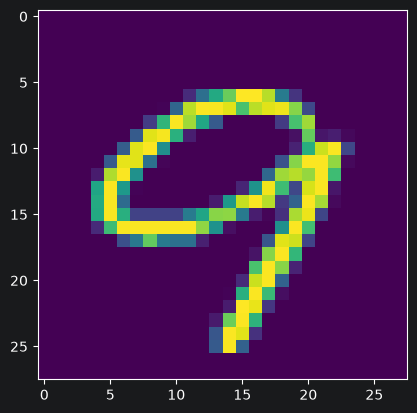

In [13]:
plt.imshow(x_test[false[0], :].reshape((28, 28)))